# The pendulum experiment
**01NAEX · Team project 1**

We study how length, release angle and mass affect a pendulum's period. The eleven sections follow the assignment, explaining the methods alongside the results.

> **Measurement details:** all times are in seconds. A timed 5 full oscillations per reading; the pilot and both B tables timed 10. Three operators took the measurements. We keep the recorded A/B/C and 1/2/3 labels without assuming an exact match between the two sets. Lengths were measured to the approximate centre of the bob.

In [1]:
from pathlib import Path
from itertools import product, combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import build_design_matrices
from IPython.display import display, Markdown

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11, 'figure.dpi': 110})
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 5)
ALPHA = .05
# Use the companion CSV locally, or load the published data when opened in Colab.
DATA_SOURCE = "https://raw.githubusercontent.com/CasualMathEnjoyer/01NAEX/project1-draft/projects/01NAEX_Project1-draft.csv"
DATA_FILENAME = "01NAEX_Project1-draft.csv"
source = next((p for p in [Path(DATA_FILENAME), Path('projects')/DATA_FILENAME]
               if p.exists()), DATA_SOURCE)
data = pd.read_csv(source)
data['T'] = data.t_N_s / data.N
data['log_T'] = np.log(data['T'])
pilot, A, B = [data.loc[data.part.eq(p)].copy() for p in ['pilot', 'A', 'B']]
def x_angle(angle):
    th = np.radians(angle)
    return np.log(1 + th**2/16 + 11*th**4/3072)
def theory_period(L, angle, g=9.81):
    return 2*np.pi*np.sqrt(np.asarray(L)/g)*np.exp(x_angle(angle))
def say(s): display(Markdown(s))
def anova(model):
    table = sm.stats.anova_lm(model, typ=2)
    table['decision (5%)'] = ['reject equal effects' if p < ALPHA else 'do not reject' if pd.notna(p) else '' for p in table['PR(>F)']]
    display(table)
    return table

def contrast(model, data, factor, low, high):
    # Average the model design matrix over the observed, balanced nuisance distribution.
    lo, hi = data.copy(), data.copy()
    lo[factor], hi[factor] = low, high
    info = getattr(model.model.data, 'design_info', None)
    if info is None:
        info = model.model.data.model_spec
    v = np.asarray(build_design_matrices([info], hi)[0]).mean(0)-np.asarray(build_design_matrices([info], lo)[0]).mean(0)
    result = model.t_test(v)
    return dict(effect=float(np.asarray(result.effect).item()), se=float(np.asarray(result.sd).item()),
                t=float(np.asarray(result.tvalue).item()), p=float(np.asarray(result.pvalue).item()),
                lower=float(result.conf_int()[0,0]), upper=float(result.conf_int()[0,1]))

## 1 · Setup and measurements
The expected period is
\[
T=2\pi\sqrt{L/g}\left(1+\theta^2/16+11\theta^4/3072\right),\qquad \theta\text{ in radians}.
\]
Length and angle multiply in this formula. Taking logarithms turns those contributions into a sum, which helps us separate their effects.

| Item | Recorded information |
|---|---|
| Lengths | 0.35, 0.65, 1.00 m; measured to the approximate centre of the bob |
| Angles | 10°, 30°, 50°; set manually by aligning the string with measured angles marked on paper. |
| B masses | 1, 2, 3 rings: 10.14, 20.22, 30.48 g |
| A mass setting | Fixed throughout; no separate mass measurement supplied |
| Timing | A: 5 full oscillations; pilot and both B tables: 10; all times in seconds |
| A layout | Two repetitions × three groups = six blocks, each containing all nine length–angle settings |
| B layout | Upper and lower 3 × 3 tables; rows 1–3, columns = ring count |

A **block** groups runs made under similar conditions. In A, the six blocks account for average differences between groups and sessions; mass stays fixed. In B, separate adjustments for each square and its rows account for session/row differences, while mass, angle and length are studied.

Timing habits, damping and counting errors can affect the results. Statistical adjustments cannot fix an incorrectly measured length; measuring to an approximate centre leaves some uncertainty in the gravity estimate.

The assignment specified two rings for the pilot and A; our records instead show three rings and three bolts. The oscillation count also differs between parts.

### Runs and periods
One observation is a timed run: $T=t_N/N$. For example, the first pilot reading gives $15.64/10=1.564$ s. Ten swings within one timing are not ten independent repeats: they share a release and stopwatch start/stop. Several people timing that same run would also give repeated measurements of one run.

Dividing by N makes periods comparable, but does not make their precision equal. Start/stop error with elapsed-time standard deviation $\sigma_t$ contributes $\sigma_t/N$ to period uncertainty. Doubling N halves this component, but not necessarily errors from length, damping or release conditions.

## 2 · Pilot study and sample size
The ten pilot runs estimate variation at one setting. We use the sample standard deviation (SD), calculated with denominator $n-1$, to plan a test of whether the three angle means differ. The target is 80% power at a 5% significance level.

For a conservative calculation, set the range of those means to the theoretical 30°−10° difference at 0.65 m, $D$. The hardest arrangement to detect places the third mean halfway between the endpoints, giving $\sum(\mu_j-\bar\mu)^2=D^2/2$. With $b$ blocks, each angle has $3b$ readings. The noncentral F calculation therefore uses
\[
\lambda=\frac{3bD^2}{2\hat\sigma^2},\qquad df_1=2,\quad df_2=8(b-1).
\]
This describes an **overall three-angle test under that conservative scenario**. It is neither a direct two-angle test nor the power for the actual theoretical 10°/30°/50° means, whose wider range is easier to detect. We repeat this same calculation in Section 11. It was made after measurement, so it is not evidence of an earlier plan.

,t_N_s,N,T
Reading index,,,
0,15.64,10,1.564
1,15.51,10,1.551
2,15.39,10,1.539
3,15.98,10,1.598
4,15.66,10,1.566
5,15.74,10,1.574
6,15.92,10,1.592
7,15.99,10,1.599
8,16.34,10,1.634


,blocks,runs,power: same period SD,"power: N=5, timing-error scenario"
0,2,18,0.18330,0.08070
1,3,27,0.30082,0.10634
2,4,36,0.41059,0.13171
3,5,45,0.51123,0.15747
4,6,54,0.60079,0.18368
5,7,63,0.67837,0.21025
6,8,72,0.74405,0.23708
7,9,81,0.79858,0.26405
8,10,90,0.84309,0.29104
9,11,99,0.87889,0.31796


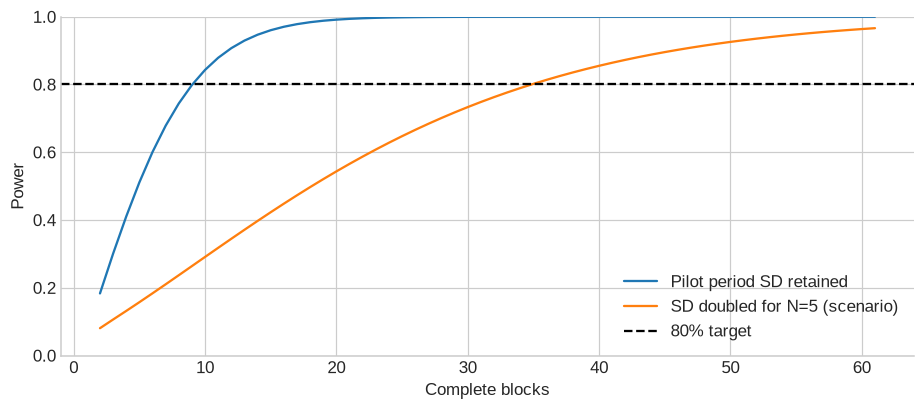

Pilot mean **1.58270 s**, SD **0.02903 s**; theory **1.64549 s**. The mean is **-3.82%** below theory. The target difference is **0.02506 s**. The same-SD calculation first reaches 80% at **10 blocks**; six blocks give **60.1%**. At four blocks power is **41.1%**.

In [2]:
display(pilot[['t_N_s','N','T']].reset_index(drop=True).rename_axis('Reading index'))
sigma = pilot['T'].std(ddof=1)
D = theory_period(.65,30)-theory_period(.65,10)
def power(b, sd):
    return stats.ncf.sf(stats.f.ppf(.95,2,8*(b-1)),2,8*(b-1),3*b*D**2/(2*sd**2))
planning = pd.DataFrame({'blocks':np.arange(2,201)})
planning['runs'] = 9*planning.blocks
planning['power: same period SD'] = [power(b,sigma) for b in planning.blocks]
planning['power: N=5, timing-error scenario'] = [power(b,2*sigma) for b in planning.blocks]
first = int(planning.loc[planning['power: same period SD'].ge(.8),'blocks'].iloc[0])
display(planning.loc[(planning.blocks<=12)|planning.blocks.eq(first)])
fig,ax=plt.subplots()
ax.plot(planning.blocks[:60],planning.iloc[:60,2],label='Pilot period SD retained')
ax.plot(planning.blocks[:60],planning.iloc[:60,3],label='SD doubled for N=5 (scenario)')
ax.axhline(.8,color='black',ls='--',label='80% target');ax.set(xlabel='Complete blocks',ylabel='Power',ylim=(0,1));ax.legend();plt.show()
say(f"Pilot mean **{pilot['T'].mean():.5f} s**, SD **{sigma:.5f} s**; theory **{theory_period(.65,30):.5f} s**. The mean is **{100*(pilot['T'].mean()/theory_period(.65,30)-1):.2f}%** below theory. The target difference is **{D:.5f} s**. The same-SD calculation first reaches 80% at **{first} blocks**; six blocks give **{power(6,sigma):.1%}**. At four blocks power is **{power(4,sigma):.1%}**.")

The recorded design contains 54 A runs, 18 B runs and 10 pilot runs. The note “80%” is a target, not an achieved result. The pilot used twice as many swings per timing as A. If start/stop error dominates, A's period SD could be about twice as large; the second curve shows this possibility, not a measured rule.

A fresh pilot using A's actual procedure would give a better planning estimate. Longer timings, better timing equipment or wider angle differences could improve detection without many extra blocks. 

One square fits 9 parameters to 9 readings, leaving no independent information to estimate error (**0 error degrees of freedom, or df**). Two squares fit 12 parameters to 18 readings, leaving **6 error df**. This assumes the same treatment effects in both squares and no interactions.

### Reading the uncertainty measures
The pilot SD, 0.02903 s, describes differences between runs. The standard error (SE) describes uncertainty in an estimate: for the pilot mean it is $0.02903/\sqrt{10}=0.00918$ s. A 5% significance level limits false rejection when the tested claim is true. Power of 80% means an 80% chance of detecting the specified effect under the assumed error model; it is not the probability that our conclusion is correct.

The planning range is only 0.02506 s. Detecting the larger 50°−10° effect with six blocks therefore does not show that six blocks were enough for this smaller target. A was also noisier than the pilot: its error SD was 0.05344 s, about 1.84 times larger.

## 3 · Run sheets
These sheets use fixed random seeds to make an example plan for a **repeat experiment**. The actual B layouts are checked in Section 4.

In [3]:
rng=np.random.default_rng(20261026)
plan_A=[]
for block in range(1,7):
    settings=list(product([.35,.65,1.],[10,30,50]))
    for order,j in enumerate(rng.permutation(9),1):
        L,angle=settings[j];plan_A.append([block,order,L,angle])
display(pd.DataFrame(plan_A,columns=['block','planned order','L_m','theta_deg']).pivot(index='planned order',columns='block',values=['L_m','theta_deg']))
def random_square(rng, square):
    i,j=np.meshgrid(np.arange(3),np.arange(3),indexing='ij')
    latin,greek=(i+j)%3,(i+2*j)%3
    r,c=rng.permutation(3),rng.permutation(3)
    latin=rng.permutation(3)[latin[r][:,c]];greek=rng.permutation(3)[greek[r][:,c]]
    out=pd.DataFrame({'square':square,'row':i.ravel()+1,'n_rings':j.ravel()+1,
                      'theta_deg':np.array([10,30,50])[latin.ravel()],
                      'L_m':np.array([.35,.65,1.])[greek.ravel()]})
    out['planned order']=rng.permutation(9)+1
    return out.sort_values('planned order')
display(pd.concat([random_square(np.random.default_rng(s),q) for q,s in [(1,20261027),(2,20261028)]],ignore_index=True))

L_m                               theta_deg                    \
block             1     2     3     4     5     6         1     2     3     4   
planned order                                                                   
1              0.35  0.65  0.65  0.65  1.00  0.35      30.0  50.0  50.0  10.0   
2              0.65  0.65  0.65  1.00  0.35  1.00      30.0  30.0  10.0  10.0   
3              1.00  1.00  1.00  0.65  1.00  0.65      30.0  10.0  30.0  50.0   
4              1.00  0.35  1.00  1.00  0.65  1.00      50.0  10.0  10.0  50.0   
5              0.65  0.35  0.35  0.35  0.65  1.00      50.0  50.0  10.0  30.0   
6              0.35  1.00  0.35  0.35  0.35  0.35      10.0  30.0  50.0  10.0   
7              1.00  0.35  0.65  0.35  0.35  0.65      10.0  30.0  30.0  50.0   
8              0.35  0.65  0.35  1.00  1.00  0.35      50.0  10.0  30.0  30.0   
9              0.65  1.00  1.00  0.65  0.65  0.65      10.0  50.0  50.0  30.0   

                           
block             5     6  
planned order              
1              30.0  50.0  
2              50.0  10.0  
3              50.0  50.0  
4              10.0  50.0  
5              30.0  30.0  
6              30.0  10.0  
7              10.0  10.0  
8              10.0  30.0  
9              50.0  30.0

,square,row,n_rings,theta_deg,L_m,planned order
0,1,3,2,50,1.00,1
1,1,1,3,50,0.65,2
2,1,1,2,10,0.35,3
3,1,3,3,30,0.35,4
4,1,3,1,10,0.65,5
5,1,2,3,10,1.00,6
6,1,2,1,50,0.35,7
7,1,1,1,30,1.00,8
8,1,2,2,30,0.65,9
9,2,3,2,30,1.00,1


Blocking, randomization and separate repeated runs serve different purposes. Blocking removes average differences between groups or sessions. Randomization stops time trends from systematically following treatment settings. Repeated runs estimate variation and improve precision.

## 4 · Data checks and summaries
We check counts, missing entries and factor codes before fitting models. Means describe the measured periods; SDs describe their spread. All 82 supplied readings are retained, including the low A readings for group C in repetition 1. The crossed-out pilot entry is omitted as requested.

n_rings,1.0,2.0,3.0
row,,,
1,Aβ,Cα,Bγ
2,Bα,Aγ,Cβ
3,Cγ,Bβ,Aα


n_rings,1.0,2.0,3.0
row,,,
1,Aγ,Cα,Bβ
2,Cβ,Bγ,Aα
3,Bα,Aβ,Cγ


82 readings retained; A complete; both B squares pairwise orthogonal.


,runs,N
part,,
A,54,5
B,18,10
pilot,10,10


date_time    82
mass_g       54
Name: Missing metadata, dtype: int64

count     mean      std
L_m  theta_deg                         
0.35 10             6  1.18100  0.04178
     30             6  1.17100  0.07177
     50             6  1.23833  0.03608
0.65 10             6  1.57567  0.07314
     30             6  1.62833  0.05952
     50             6  1.64933  0.12569
1.00 10             6  1.93467  0.08422
     30             6  1.99933  0.06362
     50             6  2.04333  0.05958

,,count,mean,std
n_rings,mass_g,,,
1.0,10.14,6,1.62717,0.36962
2.0,20.22,6,1.58850,0.30449
3.0,30.48,6,1.60133,0.40406


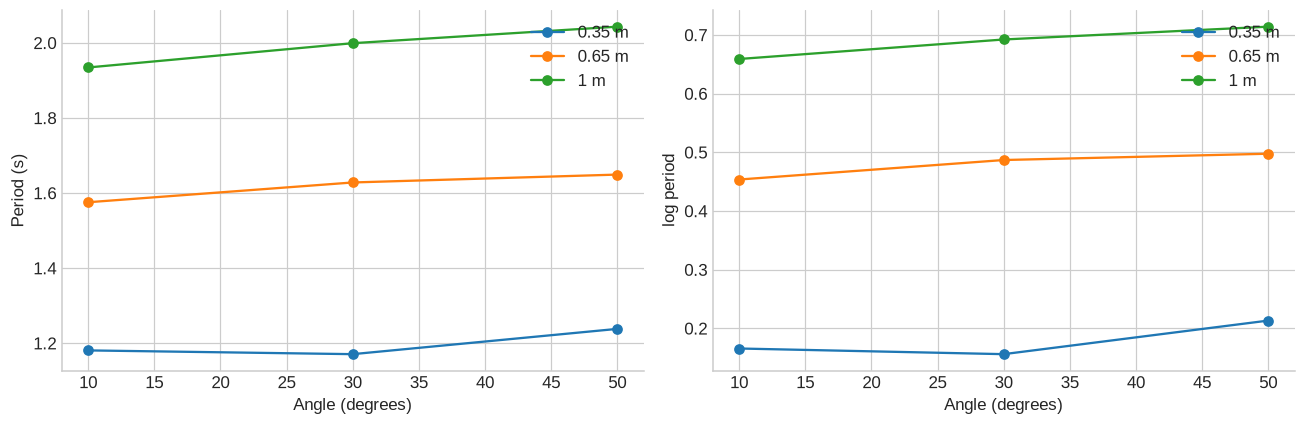

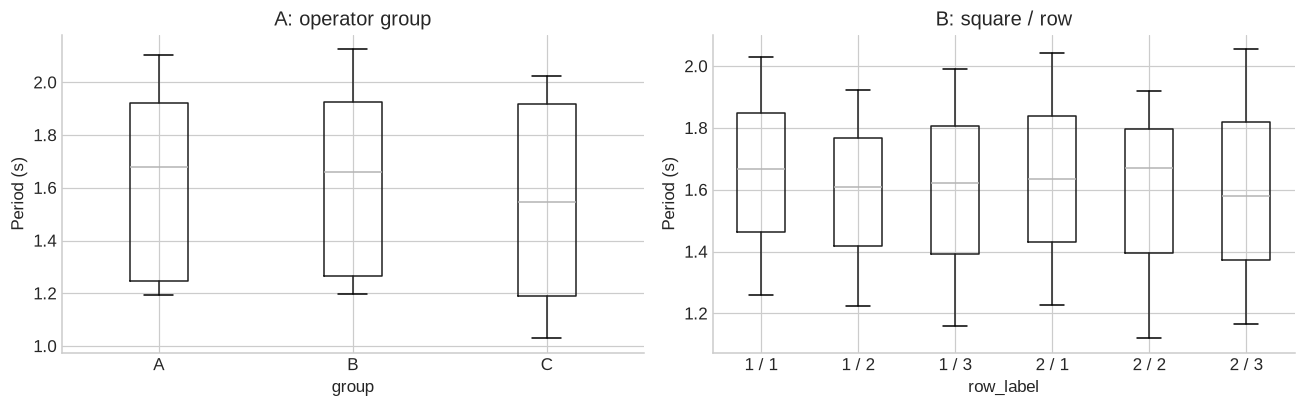

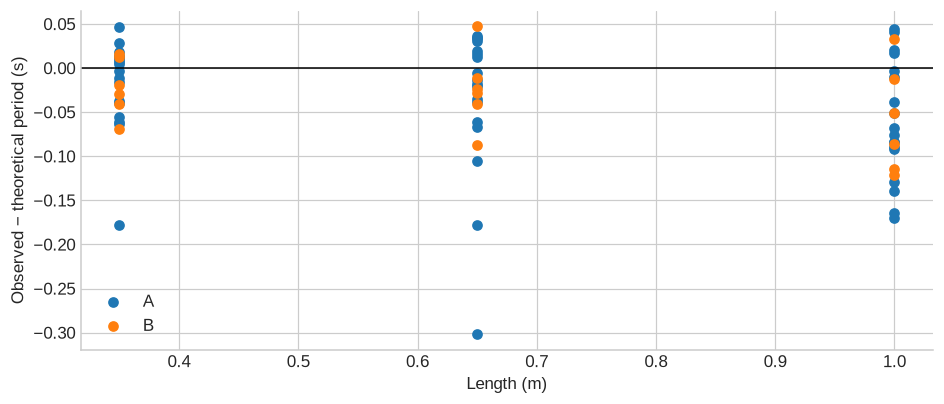

In [4]:
assert len(pilot)==10 and len(A)==54 and len(B)==18
assert data[['L_m','theta_deg','N','t_N_s']].notna().all().all()
assert (data[['L_m','N','t_N_s']]>0).all().all()
assert A.groupby(['block','L_m','theta_deg']).size().eq(1).all()
assert A.groupby('block').size().eq(9).all()
for sq,g in B.groupby('square'):
    assert len(g)==9
    for f1,f2 in combinations(['row','n_rings','theta_deg','L_m'],2):
        assert g.groupby([f1,f2]).size().eq(1).all() and len(g.groupby([f1,f2]))==9
    assert all({'A':10,'B':30,'C':50}[c[0]]==a and {'α':.35,'β':.65,'γ':1.}[c[1]]==L for c,a,L in zip(g.code,g.theta_deg,g.L_m))
    display(g.pivot(index='row',columns='n_rings',values='code'))
print('82 readings retained; A complete; both B squares pairwise orthogonal.')
display(data.groupby('part').agg(runs=('T','size'),N=('N','first')))
display(data[['date_time','mass_g']].isna().sum().rename('Missing metadata'))
display(A.groupby(['L_m','theta_deg'])['T'].agg(['count','mean','std']))
display(B.groupby(['n_rings','mass_g'])['T'].agg(['count','mean','std']))
fig,axs=plt.subplots(1,2,figsize=(12,4))
for L,g in A.groupby('L_m'):
    for ax,response in zip(axs,['T','log_T']):
        means=g.groupby('theta_deg')[response].mean()
        ax.plot(means.index,means.values,'o-',label=f'{L:g} m')
for ax,y in zip(axs,['Period (s)','log period']):ax.set(xlabel='Angle (degrees)',ylabel=y);ax.legend()
plt.tight_layout();plt.show()
fig,axs=plt.subplots(1,2,figsize=(12,4))
A.boxplot(column='T',by='group',ax=axs[0]);axs[0].set(title='A: operator group',ylabel='Period (s)')
B.assign(row_label=B.square.astype(str)+' / '+B.row.astype(str)).boxplot(column='T',by='row_label',ax=axs[1]);axs[1].set(title='B: square / row',ylabel='Period (s)')
plt.suptitle('');plt.tight_layout();plt.show()
fig,ax=plt.subplots()
for label,g in [('A',A),('B',B)]:
    ax.scatter(g.L_m,g['T']-theory_period(g.L_m,g.theta_deg),label=label)
ax.axhline(0,color='black',lw=1);ax.set(xlabel='Length (m)',ylabel='Observed − theoretical period (s)');ax.legend();plt.show()

Each mass was tested at all three lengths, so its raw SD includes the large length effect as well as noise. The model separates these sources before estimating uncertainty. The balanced layout still makes the raw mean for each mass useful.

The plots compare angle effects in seconds and on the log scale, and show departures from theory at each length. Three operators contributed; labels are kept as recorded without matching letters to numbers.

## 5 · Part A: length, angle and blocks
We fit $T\sim C(\mathrm{block})+C(L)*C(\theta)$ and repeat for $\log T$. Here `C` treats settings as categories; `*` includes their separate effects and their interaction. Blocks account for the average shift in each group–session combination.

For each ANOVA test, $H_0$ means equal adjusted averages, or no interaction; $H_1$ means at least one difference. The tables show F, df, p and the decision at 5%. An average effect across settings need not be the same at every setting.

In [5]:
a_formula='C(block) + C(L_m)*C(theta_deg)'
a_raw=smf.ols('T ~ '+a_formula,A).fit()
a_log=smf.ols('log_T ~ '+a_formula,A).fit()
say('**Period scale**');at=anova(a_raw)
say('**Log scale**');al=anova(a_log)
def tukey(model, frame, factor='theta_deg'):
    results=[]
    for low,high in combinations(sorted(frame[factor].unique()),2):
        c=contrast(model,frame,factor,low,high)
        q=abs(c['effect'])/(c['se']/np.sqrt(2))
        half=stats.studentized_range.ppf(.95,3,model.df_resid)*c['se']/np.sqrt(2)
        results.append({'contrast':f'{high:g} − {low:g}','difference':c['effect'],'lower':c['effect']-half,'upper':c['effect']+half,
                        'q':q,'p_adj':stats.studentized_range.sf(q,3,model.df_resid)})
    out=pd.DataFrame(results);out['reject equal means']=out.p_adj<.05
    return out
say('**Tukey: marginal log-angle contrasts, model residual MSE and df**');display(tukey(a_log,A))
# Simple contrasts are also shown, whether or not the interaction test rejects.
for L,g in A.groupby('L_m'):
    tab=tukey(a_log,g)
    pairs=list(combinations([10,30,50],2))
    tab['theory log difference']=[x_angle(hi)-x_angle(lo) for lo,hi in pairs]
    tab['observed change %']=100*np.expm1(tab.difference)
    say(f'**At L = {L:g} m** (Tukey controls the three comparisons within this length)');display(tab)
crd=smf.ols('T ~ C(L_m)*C(theta_deg)',A).fit()
RE=crd.mse_resid/a_raw.mse_resid
# df correction often used for small-sample relative efficiency.
RE_df=RE*((a_raw.df_resid+1)*(crd.df_resid+3))/((a_raw.df_resid+3)*(crd.df_resid+1))
say(f"Interaction p: **{at.loc['C(L_m):C(theta_deg)','PR(>F)']:.4g}** on T and **{al.loc['C(L_m):C(theta_deg)','PR(>F)']:.4g}** on log T. Block F = **{at.loc['C(block)','F']:.3f}**, p = **{at.loc['C(block)','PR(>F)']:.4g}**. Ignoring blocks gives MSE **{crd.mse_resid:.6f}**, versus **{a_raw.mse_resid:.6f}** with blocks. Relative efficiency MSE(CRD)/MSE(RCBD) = **{RE:.3f}**; with the small-df correction, **{RE_df:.3f}**.")

**Period scale**

,sum_sq,df,F,PR(>F),decision (5%)
C(block),0.12366,5.0,8.65996,1.25231e-05,reject equal effects
C(L_m),5.70421,2.0,998.69048,7.24027e-35,reject equal effects
C(theta_deg),0.05765,2.0,10.09306,2.82665e-04,reject equal effects
C(L_m):C(theta_deg),0.01133,4.0,0.99173,4.23190e-01,do not reject
Residual,0.11423,40.0,NaN,NaN,


**Log scale**

,sum_sq,df,F,PR(>F),decision (5%)
C(block),0.05479,5.0,9.47976,5.07804e-06,reject equal effects
C(L_m),2.36725,2.0,1023.96982,4.43446e-35,reject equal effects
C(theta_deg),0.02186,2.0,9.45760,4.33165e-04,reject equal effects
C(L_m):C(theta_deg),0.00494,4.0,1.06772,3.85142e-01,do not reject
Residual,0.04624,40.0,NaN,NaN,


**Tukey: marginal log-angle contrasts, model residual MSE and df**

,contrast,difference,lower,upper,q,p_adj,reject equal means
0,30 − 10,0.01895,-0.00864,0.04653,2.36451,0.22837,False
1,50 − 10,0.04888,0.02130,0.07646,6.09953,0.00030,True
2,50 − 30,0.02993,0.00235,0.05751,3.73502,0.03084,True


... (3 outputs left out)

,contrast,difference,lower,upper,q,p_adj,reject equal means,theory log difference,observed change %
0,30 − 10,0.03324,-0.01453,0.08102,2.39506,0.22012,False,0.01535,3.38021
1,50 − 10,0.04398,-0.00379,0.09176,3.16890,0.07651,False,0.04657,4.49658
2,50 − 30,0.01074,-0.03704,0.05852,0.77383,0.84850,False,0.03122,1.07987


**At L = 1 m** (Tukey controls the three comparisons within this length)

,contrast,difference,lower,upper,q,p_adj,reject equal means,theory log difference,observed change %
0,30 − 10,0.03324,-0.01453,0.08102,2.39509,0.22012,False,0.01535,3.38025
1,50 − 10,0.05508,0.00731,0.10286,3.96845,0.02061,True,0.04657,5.66272
2,50 − 30,0.02184,-0.02594,0.06961,1.57336,0.51207,False,0.03122,2.20784


Interaction p: **0.4232** on T and **0.3851** on log T. Block F = **8.660**, p = **1.252e-05**. Ignoring blocks gives MSE **0.005286**, versus **0.002856** with blocks. Relative efficiency MSE(CRD)/MSE(RCBD) = **1.851**; with the small-df correction, **1.842**.

Blocking improved precision: a relative efficiency above one means the error estimate is smaller with blocks than without them. This compares two analyses of the same data, not two newly randomized experiments. The six blocks represent group–session combinations, not six independent operators.

### Interpreting the tests
ANOVA compares variation explained by an effect with unexplained variation: $F=MS_{\mathrm{effect}}/MS_E$. A fits 14 parameters: one overall level, five block differences, two length differences, two angle differences and four interaction terms. This leaves $54-14=40$ error df. Large F values count against $H_0$, provided the error assumptions are reasonable.

An **interaction** means that one factor's effect depends on another. A 5% angle increase adds more seconds to a long pendulum's period than to a short one's. On the log scale, $T=f(L)h(\theta)$ becomes $\log T=\log f(L)+\log h(\theta)$, so this theoretical interaction disappears. We prefer that scale for comparing A and B. Our interaction p-values (0.423 for T, 0.385 for log T) do not establish an interaction, but cannot prove its absence.

The overall angle test does not identify which pairs differ. **Tukey comparisons** do this while limiting the chance of a false positive across three comparisons, using the fitted model's error estimate and df. An unblocked test would lose the block adjustment. Here the protection applies separately to each three-angle set, not to all comparisons at all lengths together.

## 6 · Part B: two Graeco–Latin squares
We fit
\[
\log T\sim C(\mathrm{square})+C(\mathrm{square}):C(\mathrm{row})+C(m)+C(\theta)+C(L).
\]
Each square has its own row adjustments; matching row numbers need not mean the same operator. There are six error df. Each F-test compares equal adjusted averages with the possibility of a difference. A row test concerns operators only if rows actually identify them. We also fit the model in seconds to compare the mass and row tests.

In [6]:
b_formula='C(square) + C(square):C(row) + C(n_rings) + C(theta_deg) + C(L_m)'
b_log=smf.ols('log_T ~ '+b_formula,B).fit();b_raw=smf.ols('T ~ '+b_formula,B).fit()
say('**Log scale**');bl=anova(b_log)
say('**Period scale**');bt=anova(b_raw)
single=B.loc[B.square.eq(1)].copy()
one_factor=smf.ols('log_T ~ C(row)+C(n_rings)+C(theta_deg)+C(L_m)',single).fit()
print('Single square: n =',len(single),'rank =',np.linalg.matrix_rank(one_factor.model.exog),'residual df =',one_factor.df_resid)
comparison=pd.DataFrame({'log F':bl.F,'log p':bl['PR(>F)'],'period F':bt.F,'period p':bt['PR(>F)']}).loc[['C(n_rings)','C(square):C(row)']]
display(comparison)
say('A single square is saturated: it interpolates all nine observations. Its residual variance and ordinary F-tests are not estimable; a perfect fit is not evidence of a perfect physical model.')

**Log scale**

,sum_sq,df,F,PR(>F),decision (5%)
C(square),0.00037,1.0,0.61642,4.62248e-01,do not reject
C(n_rings),0.00151,2.0,1.26343,3.48406e-01,do not reject
C(theta_deg),0.00457,2.0,3.81386,8.53461e-02,do not reject
C(L_m),0.80588,2.0,672.49393,8.75991e-08,reject equal effects
C(square):C(row),0.00625,4.0,2.60595,1.41590e-01,do not reject
Residual,0.00360,6.0,NaN,NaN,


**Period scale**

,sum_sq,df,F,PR(>F),decision (5%)
C(square),0.00027,1.0,0.17594,6.89487e-01,do not reject
C(n_rings),0.00465,2.0,1.50409,2.95489e-01,do not reject
C(theta_deg),0.00868,2.0,2.80578,1.37969e-01,do not reject
C(L_m),1.93043,2.0,623.83670,1.09623e-07,reject equal effects
C(square):C(row),0.01430,4.0,2.30991,1.72030e-01,do not reject
Residual,0.00928,6.0,NaN,NaN,


Single square: n = 9 rank = 9 residual df = 0.0


,log F,log p,period F,period p
C(n_rings),1.26343,0.34841,1.50409,0.29549
C(square):C(row),2.60595,0.14159,2.30991,0.17203


A single square is saturated: it interpolates all nine observations. Its residual variance and ordinary F-tests are not estimable; a perfect fit is not evidence of a perfect physical model.

### Limits of the square design
One square fits every reading exactly because its nine parameters use all nine observations. It cannot separately estimate noise or support ordinary F-tests. The second square provides six error df, assuming common effects and negligible interactions.

The layout separates the included main effects; this is called **orthogonality**. It does not separate every possible explanation. In one 3 × 3 square, the four length–angle interaction terms overlap exactly with the four mass and row terms. An interaction can therefore appear to be a mass or row effect—called **aliasing**. A second square adds information but still cannot estimate all interactions.

Pendulum theory supports adding the effects on log T, making it a better choice here than seconds. This does not remove damping, measurement bias or other departures from the model. Mass and row conclusions still depend on this assumption.

## 7 · Length dependence and gravity
So far we have compared settings as categories. We now use their numerical values to test the physical relationship:
\[
\log T=\beta_0+\beta_1\log L+\beta_2x(\theta)+\beta_3(m-m_*)+\text{group/session adjustments},
\]
where $x(\theta)=\log(1+\theta^2/16+11\theta^4/3072)$. The fourth-order term and logarithm describe the angle correction at 50° better than plain $\theta^2$.

A's bolt mass is unknown. For B, we subtract the mean ring mass; for A, we set this mass variable to zero. A separate starting level for each A block and each B square–row absorbs A's unknown constant mass and average timing differences. Thus B supplies the mass slope; A's mass is not invented. Separate operator terms would duplicate these adjustments. We assume length and angle slopes are shared by both parts.

To estimate g, fix the length slope at $1/2$ and the angle slope at 1. The coding makes the overall starting level, $\beta_0$, an equally weighted average across the 12 groups: A at its actual unknown bolt mass, B at its mean ring mass. This cannot separately identify absolute timing bias. Its confidence interval assumes the supplied lengths, angles, units and N are correct and excludes calibration uncertainty.

In [7]:
pooled=pd.concat([A,B],ignore_index=True)
pooled['stratum']=[f'A_block_{int(r.block)}' if r.part=='A' else f'B_square_{int(r.square)}_row_{int(r.row)}' for r in pooled.itertuples()]
mstar=B.mass_g.mean();mass_range=B.mass_g.max()-B.mass_g.min()
pooled['mass_centered']=np.where(pooled.part.eq('B'),pooled.mass_g-mstar,0.)
pooled['log_L']=np.log(pooled.L_m);pooled['x']=x_angle(pooled.theta_deg)
numeric=smf.ols('log_T ~ log_L + x + mass_centered + C(stratum, Sum)',pooled).fit()
display(pd.DataFrame({'estimate':numeric.params,'SE':numeric.bse,'lower95':numeric.conf_int()[0],'upper95':numeric.conf_int()[1]}).loc[['Intercept','log_L','x','mass_centered']])
for hypothesis in ['log_L = 0.5','x = 1']:
    test=numeric.t_test(hypothesis)
    say(f"H₀: **{hypothesis}**, H₁: unequal. t({numeric.df_resid:.0f}) = **{float(np.asarray(test.tvalue).item()):.3f}**, p = **{float(np.asarray(test.pvalue).item()):.4g}** → **{'reject' if test.pvalue < .05 else 'do not reject'}** at 5%.")
single=single.assign(log_L=np.log(single.L_m),x=x_angle(single.theta_deg),mass_centered=single.mass_g-mstar)
one_numeric=smf.ols('log_T ~ log_L+x+mass_centered+C(row)',single).fit()
print('One-square numeric model: rank',np.linalg.matrix_rank(one_numeric.model.exog),'residual df',one_numeric.df_resid,'(factor model: 0).')
pooled['adjusted']=pooled.log_T-.5*pooled.log_L-pooled.x
fixed=smf.ols('adjusted ~ mass_centered + C(stratum, Sum)',pooled).fit()
def gravity(model):
    intercept=model.params['Intercept'];lo,hi=model.conf_int().loc['Intercept']
    return (2*np.pi)**2*np.exp(-2*np.array([intercept,hi,lo]))
g_est,g_lo,g_hi=gravity(fixed)
display(pd.DataFrame([{'population':'Equal-weight pooled strata','g':g_est,'lower95':g_lo,'upper95':g_hi}]))
for part,frame in pooled.groupby('part'):
    form='adjusted ~ C(stratum, Sum)' + (' + mass_centered' if part=='B' else '')
    gm=smf.ols(form,frame).fit();gg=gravity(gm)
    say(f'**{part}-only sensitivity:** g = {gg[0]:.4f}, 95% CI [{gg[1]:.4f}, {gg[2]:.4f}] m/s².')
say(f"The pooled conditional estimate is **{g_est:.4f} m/s²**, 95% CI **[{g_lo:.4f}, {g_hi:.4f}]**; 9.81 is **{'inside' if g_lo <= 9.81 <= g_hi else 'outside'}** this interval. Estimated length exponent: **{numeric.params['log_L']:.4f}**; angle coefficient: **{numeric.params['x']:.3f}**.")

,estimate,SE,lower95,upper95
Intercept,0.66836,0.00737,0.65360,0.68312
log_L,0.48718,0.00856,0.47005,0.50431
x,0.98216,0.19023,0.60124,1.36309
mass_centered,-0.00104,0.00089,-0.00282,0.00074


H₀: **log_L = 0.5**, H₁: unequal. t(57) = **-1.498**, p = **0.1395** → **do not reject** at 5%.

H₀: **x = 1**, H₁: unequal. t(57) = **-0.094**, p = **0.9256** → **do not reject** at 5%.

One-square numeric model: rank 6 residual df 3.0 (factor model: 0).


,population,g,lower95,upper95
0,Equal-weight pooled strata,10.2491,10.07562,10.42556


**A-only sensitivity:** g = 10.2739, 95% CI [10.0882, 10.4629] m/s².

**B-only sensitivity:** g = 10.2244, 95% CI [10.0076, 10.4459] m/s².

The pooled conditional estimate is **10.2491 m/s²**, 95% CI **[10.0756, 10.4256]**; 9.81 is **outside** this interval. Estimated length exponent: **0.4872**; angle coefficient: **0.982**.

### Meaning of the fitted relationship
Multiplying length by $k$ multiplies the fitted period by $k^{\beta_1}$. Our exponent 0.4872 is compatible with the expected 0.5; doubling length predicts about a 40% increase in period. The angle coefficient 0.982 is compatible with the expected 1.

Each numerical slope replaces two category differences with one parameter. For one square, this leaves three error df instead of zero. The gain comes from assuming a particular response shape, not from extra data.

Slopes describe changes between settings; the starting level describes the overall period. A common multiplicative timing or length error can shift the level while leaving the slopes correct. With theoretical slopes fixed,
\[
g=(2\pi)^2e^{-2\beta_0}.
\]
Because this decreases as $\beta_0$ increases, we reverse the confidence-interval endpoints when transforming them. The interval around 10.2491 m/s² excludes 9.81, but does not include possible calibration errors. More repeats can narrow the interval without removing a consistent bias.

First check length from pivot to centre of mass, then counting, timing, N, angle setting and damping. A 1 cm length error changes g by roughly $0.01/L$ in relative terms; finite ring size also changes the effective length. An estimate of g that is too high can reflect periods that are too short or recorded lengths that are too large. Group timing habits can shift it too; these data cannot identify the cause.

The reported g is therefore conditional on the model and the chosen group average. Reading it as a physical measurement also assumes no average systematic timing error.

## 8 · Mass and practical importance
A test that fails to detect a difference does not show that the difference is small. We compare three rings with one ring and ask whether the period change is within **±0.5%**. Because $g\propto T^{-2}$, that is about a 1% effect on g. We chose this practical limit after measurement, not in advance.

We use **two one-sided tests (TOST)**. For the log-period difference $d$, the null claim is $d\le\log(0.995)$ or $d\ge\log(1.005)$; the alternative is that d lies between those limits. Both one-sided p-values must be below 0.05. Equivalently, the central 90% confidence interval must fit entirely inside the limits.

We check both the category model and the numerical mass model. They reuse data and are alternative analyses, not independent repeats.

In [8]:
mass_factor=contrast(b_log,B,'n_rings',1,3)
est=numeric.params['mass_centered']*mass_range
se=numeric.bse['mass_centered']*mass_range
mass_numeric={'effect':est,'se':se}
def mass_result(label,c,df):
    d,se=c['effect'],c['se'];lo_margin,hi_margin=np.log(.995),np.log(1.005)
    ci95=d+np.array([-1,1])*stats.t.ppf(.975,df)*se
    ci90=d+np.array([-1,1])*stats.t.ppf(.95,df)*se
    tl=(d-lo_margin)/se;tu=(d-hi_margin)/se
    pl=stats.t.sf(tl,df);pu=stats.t.cdf(tu,df)
    return {'model':label,'effect %':100*np.expm1(d),'95% low':100*np.expm1(ci95[0]),'95% high':100*np.expm1(ci95[1]),
            '90% low':100*np.expm1(ci90[0]),'90% high':100*np.expm1(ci90[1]),'df':df,
            't lower':tl,'p lower':pl,'t upper':tu,'p upper':pu,'TOST p':max(pl,pu),'equivalent':max(pl,pu)<.05}
equiv=pd.DataFrame([mass_result('B categorical',mass_factor,b_log.df_resid),mass_result('Pooled numeric',mass_numeric,numeric.df_resid)])
display(equiv)
for r in equiv.to_dict('records'):
    say(f"**{r['model']}:** estimated change **{r['effect %']:.2f}%**, 95% CI **[{r['95% low']:.2f}%, {r['95% high']:.2f}%]**. TOST p = **{r['TOST p']:.4g}**: **{'equivalence established at this margin' if r['equivalent'] else 'equivalence not established at ±0.5%'}**.")

,model,effect %,95% low,95% high,90% low,90% high,df,t lower,p lower,t upper,p upper,TOST p,equivalent
0,B categorical,-2.09822,-5.42588,1.34651,-4.75021,0.62759,6.0,-1.14580,0.85224,-1.85340,0.05663,0.85224,False
1,Pooled numeric,-2.09446,-5.57165,1.51077,-5.00649,0.90684,57.0,-0.89456,0.81261,-1.44832,0.07650,0.81261,False


**B categorical:** estimated change **-2.10%**, 95% CI **[-5.43%, 1.35%]**. TOST p = **0.8522**: **equivalence not established at ±0.5%**.

**Pooled numeric:** estimated change **-2.09%**, 95% CI **[-5.57%, 1.51%]**. TOST p = **0.8126**: **equivalence not established at ±0.5%**.

The category-model estimate is −2.10%, with a 95% interval of −5.43% to 1.35%. It includes zero and changes much larger than ±0.5%. We therefore establish neither a difference from zero nor a negligible effect.

The numerical model additionally assumes a linear mass effect from 10.14 to 30.48 g. Failure of either equivalence test does not prove mass matters; it means a practically relevant effect cannot be ruled out.

## 9 · Model checks
A **residual** is the observed value minus the fitted value. Residuals should lie around zero without curves, widening spread or patterns across settings or time. Normal Q–Q plots check whether a normal error distribution is plausible. With only six error df, B's checks are weak. All readings remain included; unusual points should be checked against notes, not removed to improve the fit.

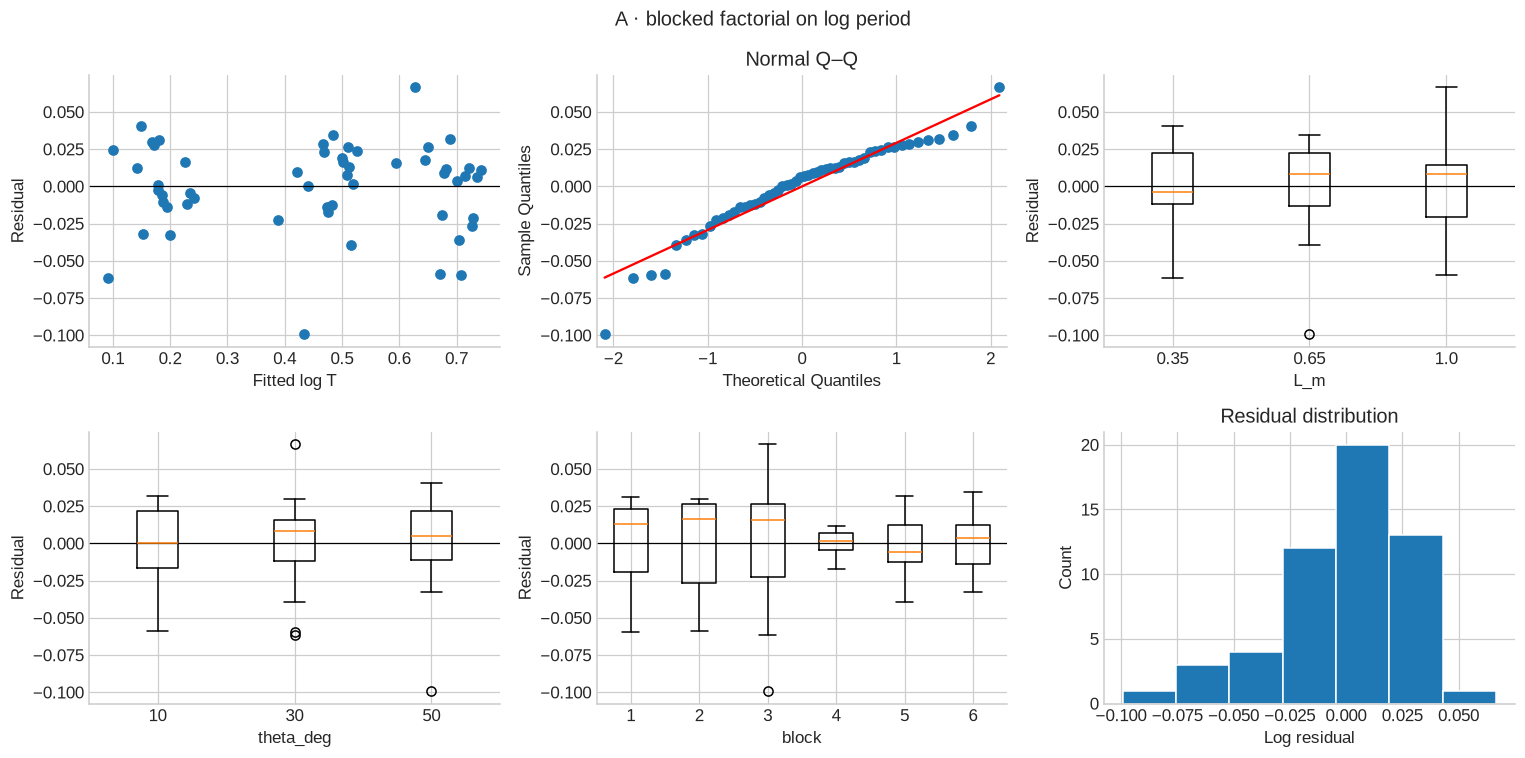

,L_m,theta_deg,block,t_N_s,residual,studentized,Cook D
33,0.65,50,3,6.98,-0.09923,-3.39104,0.28748
29,1.00,30,3,10.01,0.06665,2.27782,0.12971
35,0.35,30,3,5.15,-0.06174,-2.10989,0.11129
11,1.00,30,1,9.56,-0.05939,-2.02970,0.10299
19,1.00,10,2,9.23,-0.05860,-2.00273,0.10027


Exploratory normality check: H₀ normal residual distribution, H₁ nonnormal; Shapiro W = **0.9468**, p = **0.018** → **reject** at 5%. Fitted residuals are correlated by estimation, so this is an approximate diagnostic, not model validation.

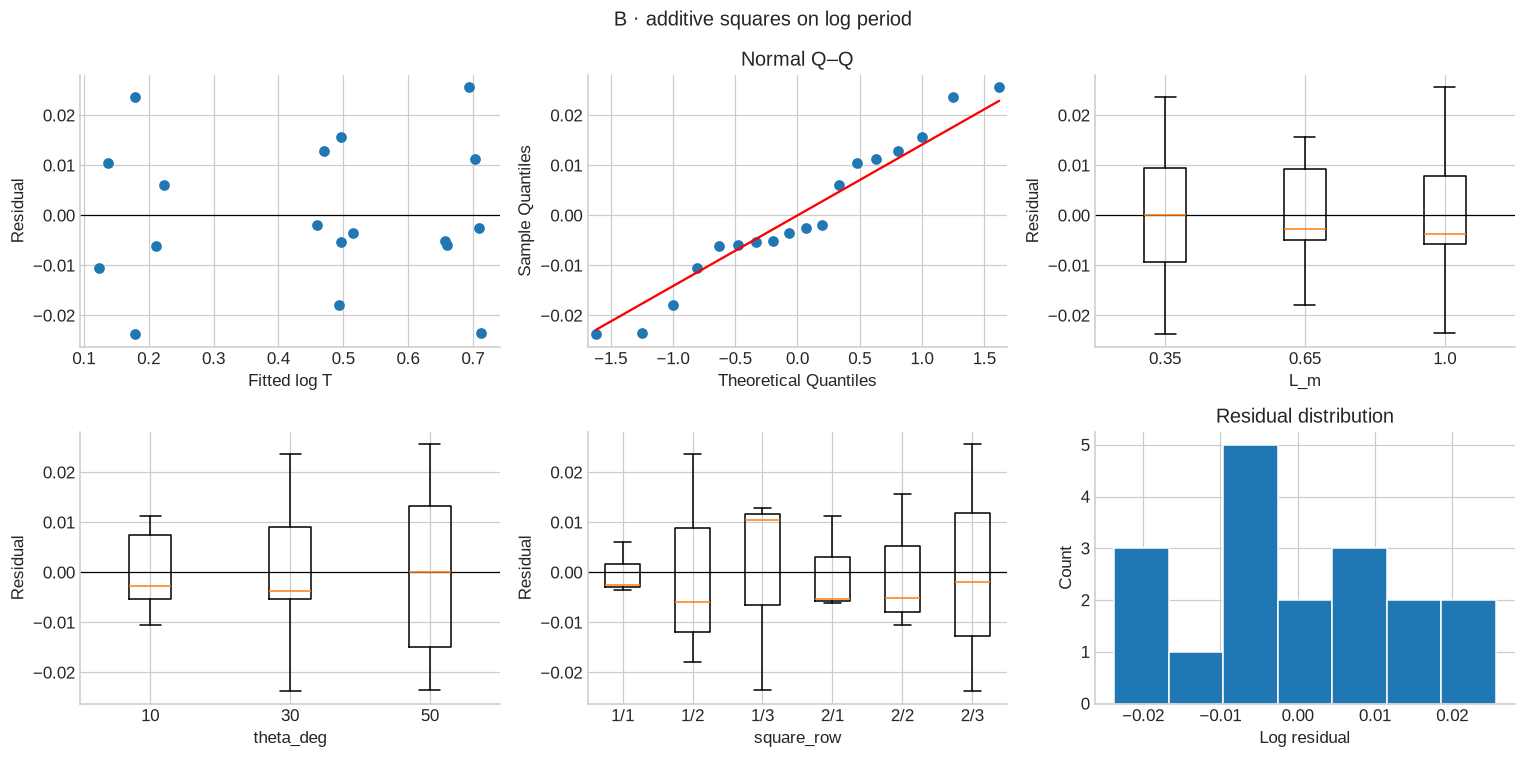

,L_m,theta_deg,square_row,t_N_s,residual,studentized,Cook D
81,1.00,50,2/3,20.55,0.02561,1.81245,0.54749
79,0.35,30,2/3,11.67,-0.02374,-1.67978,0.47027
67,0.35,30,1/2,12.24,0.02374,1.67978,0.47027
70,1.00,50,1/3,19.91,-0.02342,-1.65742,0.45784
69,0.65,50,1/2,16.10,-0.01784,-1.26201,0.26545


Exploratory normality check: H₀ normal residual distribution, H₁ nonnormal; Shapiro W = **0.9551**, p = **0.5109** → **do not reject** at 5%. Fitted residuals are correlated by estimation, so this is an approximate diagnostic, not model validation.

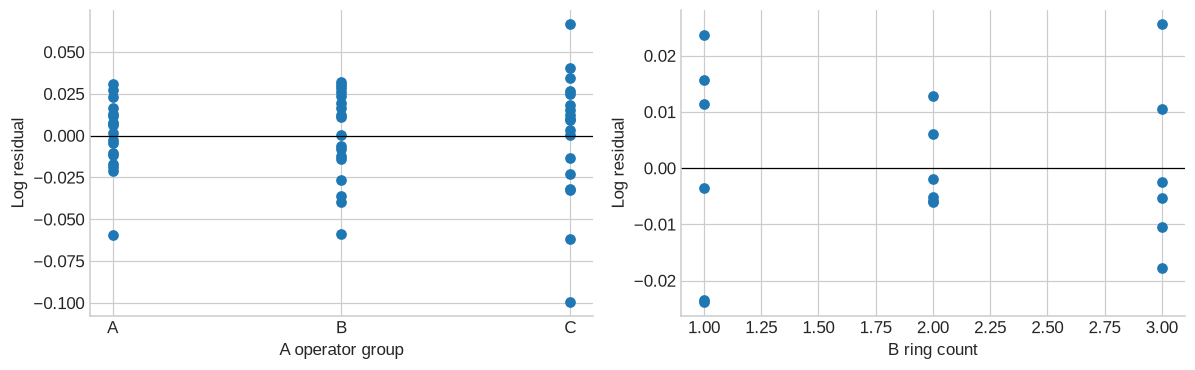

In [9]:
def diagnostics(model,frame,label,group):
    fig,axs=plt.subplots(2,3,figsize=(14,7))
    res=model.resid
    axs[0,0].scatter(model.fittedvalues,res);axs[0,0].set(xlabel='Fitted log T',ylabel='Residual')
    sm.qqplot(res,line='s',ax=axs[0,1]);axs[0,1].set_title('Normal Q–Q')
    for ax,factor in [(axs[0,2],'L_m'),(axs[1,0],'theta_deg'),(axs[1,1],group)]:
        tmp=frame.copy();tmp['residual']=res
        levels=sorted(tmp[factor].unique())
        ax.boxplot([tmp.loc[tmp[factor].eq(x),'residual'] for x in levels],tick_labels=[str(x) for x in levels])
        ax.set(xlabel=factor,ylabel='Residual')
    axs[1,2].hist(res, bins=7, edgecolor='white')
    axs[1,2].set(xlabel='Log residual', ylabel='Count', title='Residual distribution')
    for ax in [axs[0,0],axs[0,2],axs[1,0],axs[1,1]]:ax.axhline(0,color='black',lw=.8)
    fig.suptitle(label);plt.tight_layout();plt.show()
    influence=model.get_influence()
    out=frame[['L_m','theta_deg',group,'t_N_s']].copy()
    out['residual']=res;out['studentized']=influence.resid_studentized_internal;out['Cook D']=influence.cooks_distance[0]
    display(out.sort_values('Cook D',ascending=False).head(5))
    sh=stats.shapiro(res)
    say(f"Exploratory normality check: H₀ normal residual distribution, H₁ nonnormal; Shapiro W = **{sh.statistic:.4f}**, p = **{sh.pvalue:.4g}** → **{'reject' if sh.pvalue<.05 else 'do not reject'}** at 5%. Fitted residuals are correlated by estimation, so this is an approximate diagnostic, not model validation.")
diagnostics(a_log,A,'A · blocked factorial on log period','block')
B['square_row']=B.square.astype(str)+'/'+B.row.astype(str)
diagnostics(b_log,B,'B · additive squares on log period','square_row')
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].scatter(A.group,a_log.resid);axs[0].set(xlabel='A operator group',ylabel='Log residual')
axs[1].scatter(B.n_rings,b_log.resid);axs[1].set(xlabel='B ring count',ylabel='Log residual')
for ax in axs:ax.axhline(0,color='black',lw=.8)
plt.tight_layout();plt.show()

A's first-repetition group C has several short periods, especially at 0.65 m. A block adjustment removes an average shift but cannot remove a shift that changes with length. The influence tables identify readings that most affect the fitted model.

A shows a pronounced negative residual tail (Shapiro p=0.018) and uneven spread between blocks. B does not reject normality (p=0.511), but its small sample offers little reassurance. With 12 parameters for 18 readings, B can follow individual observations closely (**high leverage**), so its small residuals should not be compared directly with A's.

Normality, equal spread, independence and the correct response pattern are separate assumptions. These checks alone do not establish independence. The standard intervals and F-tests, including those for the combined A/B model, should therefore be treated as approximate. The gravity discrepancy is not evidence of a new physical value.

## 10 · Comparing the designs
We compare the 50°−10° angle difference and the 1.00−0.35 m length difference on log T. A averages over its full set of combinations; B assumes each effect is independent of the other settings. Each SE comes from its own fitted model.

To compare precision per run, multiply the estimated variance by the number of runs; smaller is better. This assumes independent, comparable runs and variance decreasing as $1/n$. Different oscillation counts, bobs and noise mean the result compares these implementations, not the designs under all conditions.

In [10]:
design_rows=[]
for label,model,frame in [('A',a_log,A),('B',b_log,B)]:
    for factor,lo,hi in [('theta_deg',10,50),('L_m',.35,1.)]:
        c=contrast(model,frame,factor,lo,hi)
        design_rows.append({'design':label,'contrast':f'{factor}: {hi} − {lo}','estimate (log)':c['effect'],'SE':c['se'],'n':len(frame),'variance × n':c['se']**2*len(frame)})
design_comparison=pd.DataFrame(design_rows);display(design_comparison)

,design,contrast,estimate (log),SE,n,variance × n
0,A,theta_deg: 50 − 10,0.04888,0.01133,54,0.00694
1,A,L_m: 1.0 − 0.35,0.51011,0.01133,54,0.00694
2,B,theta_deg: 50 − 10,0.03874,0.01413,18,0.00360
3,B,L_m: 1.0 − 0.35,0.51420,0.01413,18,0.00360


For both differences, A has the smaller SE: 0.01133 versus B's 0.01413. A is more precise overall, but uses 54 rather than 18 runs. B's variance × runs is 0.00360 versus 0.00694 for A—about 52% as large. B timed twice as many swings per run, so this does not show greater precision per minute or protection against interaction bias.

| Feature | A: 54-run factorial | B: two squares, 18 runs |
|---|---|---|
| Length and angle | Separate effects and their interaction | Separate effects, assuming no interaction |
| Mass | Fixed; no comparison | Three levels |
| Group/session adjustment | Six blocks | Square and rows within square |
| Error df | 40 | 6 |
| Main limitation | Setting-dependent block effects enter the error estimate | Interactions can be mistaken for separate factor effects |
| Timed oscillations | 270 | 180 |

A checks length–angle interaction; B studies mass. Neither identifies named-operator effects without the missing mapping. Theory supports the log-scale assumption for B, but our checks do not prove it.

**With only 18 runs**, choose two independently randomized squares to study length, angle and mass together, with the numerical physics model as an additional analysis. This gives up interaction checks and may still be too imprecise for ±0.5% mass equivalence. If interactions were the priority, repeated full factorial combinations would be preferable; keeping mass fixed cannot answer the mass question.

## 11 · Conclusions and improvements
We repeat Section 2's conservative overall-angle power calculation using A's measured error SD. The target stays fixed. This assesses precision under that scenario, rather than calculating “observed power” from the effect we happened to measure. Confidence intervals remain necessary.

In [11]:
sigma_main=np.sqrt(a_raw.mse_resid)
actual_power=power(6,sigma_main)
say(f"A residual SD is **{sigma_main:.5f} s**, versus pilot **{sigma:.5f} s** (ratio **{sigma_main/sigma:.2f}**). With six blocks and the target D = **{D:.5f} s**, plug-in power is **{actual_power:.1%}**. The pilot precision did not transfer directly to the shorter A timings and different bob/block conditions.")
angle=contrast(a_log,A,'theta_deg',10,50)
angle_theory=100*np.expm1(x_angle(50)-x_angle(10))
say(f"**1. Length and gravity.** The pooled fitted exponent is **{numeric.params['log_L']:.4f}** (95% CI **{numeric.conf_int().loc['log_L',0]:.4f}–{numeric.conf_int().loc['log_L',1]:.4f}**). The constrained, nuisance-averaged g estimate is **{g_est:.4f} m/s²** (95% CI **{g_lo:.4f}–{g_hi:.4f}**), conditional on the timing and calibration assumptions.")
say(f"**2. Large angles.** In A, the adjusted 50°−10° change is **{100*np.expm1(angle['effect']):.2f}%** (pointwise 95% CI **{100*np.expm1(angle['lower']):.2f}%–{100*np.expm1(angle['upper']):.2f}%**), versus theory **{angle_theory:.2f}%**. The model contrast tests H₀: zero log difference against H₁: nonzero; t({a_log.df_resid:.0f}) = **{angle['t']:.3f}**, p = **{angle['p']:.4g}**, so **{'reject' if angle['p']<.05 else 'do not reject'}**. Section 5 gives the multiplicity-adjusted Tukey results; Section 7 separately tests agreement with the theoretical angle coefficient.")
say('**3. Mass.** '+('The categorical B model establishes equivalence at ±0.5%.' if equiv.iloc[0]['equivalent'] else 'The categorical B model does not establish equivalence at ±0.5%; a non-significant mass F-test cannot establish irrelevance.'))
say('**4. Designs.** The squares study more factors with fewer runs, but need additivity and leave only six error df. The factorial estimates length–angle interaction and has a much stronger residual estimate, but its fixed bob cannot test mass.')

A residual SD is **0.05344 s**, versus pilot **0.02903 s** (ratio **1.84**). With six blocks and the target D = **0.02506 s**, plug-in power is **21.0%**. The pilot precision did not transfer directly to the shorter A timings and different bob/block conditions.

**1. Length and gravity.** The pooled fitted exponent is **0.4872** (95% CI **0.4700–0.5043**). The constrained, nuisance-averaged g estimate is **10.2491 m/s²** (95% CI **10.0756–10.4256**), conditional on the timing and calibration assumptions.

**2. Large angles.** In A, the adjusted 50°−10° change is **5.01%** (pointwise 95% CI **2.63%–7.44%**), versus theory **4.77%**. The model contrast tests H₀: zero log difference against H₁: nonzero; t(40) = **4.313**, p = **0.0001024**, so **reject**. Section 5 gives the multiplicity-adjusted Tukey results; Section 7 separately tests agreement with the theoretical angle coefficient.

**3. Mass.** The categorical B model does not establish equivalence at ±0.5%; a non-significant mass F-test cannot establish irrelevance.

**4. Designs.** The squares study more factors with fewer runs, but need additivity and leave only six error df. The factorial estimates length–angle interaction and has a much stronger residual estimate, but its fixed bob cannot test mass.

**For a repeat with the same time budget:** use the same oscillation count throughout and pilot that exact procedure. Improve timing with video or a photogate if available, measure pivot-to-centre-of-mass length carefully, keep bob arrangements comparable and retain the wide angle range. Record operators and anomalies, and remeasure suspicious settings. Plan repeats around the desired precision for mass, not just detection of the large length effect.

**Running the report:** keep the companion CSV with the notebook and run cells in order. The packages are numpy, pandas, scipy, statsmodels, matplotlib, patsy and Jupyter. Local runs need no network. Calculations and saved results use the companion CSV. The methods and theory come from `projects/01NAEX_Project1.ipynb`.